# Análise Exploratória dos Dados

O presente notebook visa a análise exploratória e a data discovery dos dados presentes no Sistema de Internações Hospitalares (SIH-RD) para garantir a confiabilidade dos dados. As frentes de investigação são as seguintes:

- Redução de dimensionalidade: avaliar as informações que cada variável contribui para uma análise sucinta ao selecionar colunas de interesse.
- Validação da qualidade dos dados: validar informações contidas nas variáveis (como as variáveis `DT_INTER`, `DT_SAIDA` e `QT_DIARIAS`).
- Integridade relacional: avaliar o cruzamento (JOIN) entre a tabela fato e as tabelas de domínio, como municípios de acordo com o IBGE e a tabela especialidades das AIHs.
- Distribuições e outliers: mapear o comportamento estatístico, como em variáveis numéricas `VAL_TOT` e `IDADE`.
- Agregações base: construir as primeiras sumarizações macro (volume de pacientes ao mês, custos por especialidade) para fundamentar análises avançadas.

## Bibliotecas

In [1]:
import os
from pathlib import Path
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

In [2]:
class MonitorMemoria:
    """
    Mapeamento e gestão dos DataFrames em Pandas 
    instanciados no notebook.
    
    """
    def __init__(self):
        # Usamos um Set (conjunto) para armazenar apenas as strings com os nomes, evitando duplicações
        self.registry = set()
        
    def add(self, nome_variavel: str):
        """Registra o nome do DataFrame para monitoramento."""
        self.registry.add(nome_variavel)
        print(f"[Monitor] '{nome_variavel}' adicionado ao rastreamento.")
        
    def status(self, env_globals: dict):
        """Calcula e exibe a memória exata alocada por cada DataFrame."""
        total_mb = 0
        print("-" * 45)
        print(f"{'DataFrame':<25} | {'Memória (MB)':<15}")
        print("-" * 45)
        
        for nome in list(self.registry):
            if nome in env_globals and isinstance(env_globals[nome], pd.DataFrame):
                # memory_usage(deep=True) varre strings e objetos para dar o tamanho real
                size_mb = env_globals[nome].memory_usage(deep=True).sum() / (1024 * 1024)
                total_mb += size_mb
                print(f"{nome:<25} | {size_mb:>10.2f} MB")
            else:
                print(f"{nome:<25} | {'(Não instanciado)':<15}")
                
        print("-" * 45)
        print(f"Total ocupado na RAM: {total_mb:.2f} MB\n")
        
    def clear(self, env_globals: dict, nome_variavel: str = None):
        """
        Deleta os objetos da memória global do Jupyter e força o Garbage Collector.
        Se nenhum nome for passado, limpa TODOS os DataFrames registrados.
        """
        alvos = [nome_variavel] if nome_variavel else list(self.registry)
        
        for nome in alvos:
            if nome in env_globals:
                # Mata a variável no nível global do Jupyter
                del env_globals[nome]
            self.registry.discard(nome)
            print(f"🗑️ '{nome}' removido com sucesso.")
            
        # Força o Python a esvaziar a lixeira e devolver a RAM para o sistema operacional (Kubuntu)
        gc.collect()
        print("[Monitor] Limpeza de memória concluída.")

    def clear_all(self, env_globals: dict):
        """
        Deleta TODOS os DataFrames registrados da memória global de uma só vez
        e força o Garbage Collector a liberar a RAM imediatamente.
        """
        if not self.registry:
            print("[Monitor] Nenhum DataFrame registrado para limpar.")
            return
            
        # Transforma em lista para não dar erro ao iterar e alterar o set ao mesmo tempo
        for nome in list(self.registry):
            if nome in env_globals:
                del env_globals[nome] # Remove a variável do Jupyter
            print(f"🗑️ '{nome}' removido com sucesso.")
            
        # Esvazia o rastreador
        self.registry.clear()
        
        # Chama o lixeiro do Python
        gc.collect()
        print("[Monitor] Limpeza total de memória concluída!")

# instanciação de monitor de memória
monitor = MonitorMemoria()

## Configuração de Cache e Caminhos para Queries

In [32]:
# configuração dos caminhos para as queries usando duckdb

# diretório base do repo
BASE_DIR = (
    Path().resolve().parent 
    if Path().resolve().name == "notebooks" 
    else Path().resolve()
)

# checagem de diretório com arquivos baixados do pacote pysus
PYSUS_CACHE_DIR = BASE_DIR / 'data' / 'raw' / 'pysus_cache'
if PYSUS_CACHE_DIR.exists():
    print("Configurando caminhos de arquivos de dados...")
    # aponta para diretório com dados brutos do SIH
    SIH_DIR = BASE_DIR / 'data' / 'raw' / 'pysus_cache' / 'downloads' / 'ducklake' / 'sih'
    # as_posix() para caminho glob (string literal, não objeto como pathlib)
    sih_glob = (SIH_DIR / '*.parquet').as_posix()

    #print(f"Padrão de busca para o DuckDB: {sih_glob}")

    # aponta para diretório de dados processados
    PROCESSED = BASE_DIR / 'data' / 'processed'

    # caminhos específicos
    ibge_path = (PROCESSED / 'ibge_municipios.parquet').as_posix()
    espec_path = (PROCESSED / 'sih_especialidades.parquet').as_posix()
    cid_path = ''
    print("Caminhos de arquivos definidos.")

    # estabelecendo conexão com duckdb
    con = duckdb.connect()
    print("Conexão com DuckDB estabelecida.")

else:
    raise FileNotFoundError(
        "Os dados brutos não foram encontrados."
        "Execute o script setup.sh presente na raiz do repositório para realizar a ingestão dos dados e rodar este notebook."
    )

Configurando caminhos de arquivos de dados...
Caminhos de arquivos definidos.
Conexão com DuckDB estabelecida.


## Verificação de Valores Únicos Para Cada Coluna

Muitas colunas não têm informações relevantes. Para selecionar as variáveis adequadas para o estudo, preciso investigar primeiramente a quantidade de valores únicos, o que proporciona uma análise mais direta da utilidade das variáveis.

In [19]:
# gera o perfil de todas as 114 colunas
df_perfil = con.execute(f"SUMMARIZE SELECT * FROM '{sih_glob}'").df()

# ordena as colunas do df para verificar o perfilamento do conjunto de dados
df_analise = df_perfil[['column_name', 'column_type', 'null_percentage', 'approx_unique']]

# tirando o limite de linhas e colunas da exibição do DF do pandas
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    
    df_ordenado = df_analise.sort_values(
        by=['null_percentage', 'approx_unique'], 
        ascending=[False, False]
    )
    print(f"Número de colunas:{df_ordenado.shape}")
    display(df_ordenado)

# deletando dataframes
del df_perfil
del df_analise

Número de colunas:(113, 4)


,column_name,column_type,null_percentage,approx_unique
5,N_AIH,VARCHAR,0.00,2144336
35,VAL_TOT,VARCHAR,0.00,426686
24,VAL_SH,VARCHAR,0.00,363506
37,US_TOT,VARCHAR,0.00,173416
25,VAL_SP,VARCHAR,0.00,73208
7,CEP,VARCHAR,0.00,50637
9,NASC,VARCHAR,0.00,42297
85,SEQUENCIA,VARCHAR,0.00,32965
65,INSC_PN,VARCHAR,0.00,22339
40,DIAG_PRINC,VARCHAR,0.00,8048


## Quality Check e Sumarização

In [22]:
# Lista de colunas validadas na etapa de Data Discovery
COLUNAS_SELECIONADAS = [
    'VAL_TOT',    # Valor total da AIH
    'DIAG_PRINC', # Código do diagnóstico principal (CID10)
    'MUNIC_RES',  # Município de residência do paciente
    'DT_INTER',   # Data de internação
    'DT_SAIDA',   # Data de saída
    'MUNIC_MOV',  # Município do estabelecimento
    'DIAS_PERM',  # Dias de permanência
    'QT_DIARIAS', # Quantidade de diárias faturadas
    'NACIONAL',   # Código da nacionalidade do paciente
    'IDADE',      # Idade (requer COD_IDADE)
    'COD_IDADE',  # Unidade de medida da idade (anos, meses, dias)
    'ESPEC',      # Especialidade do leito
    'MARCA_UTI',  # Tipo de UTI utilizada
    'RACA_COR',   # Raça/cor do paciente
    'SEXO',       # Sexo do paciente
    'IDENT',      # Identificação da AIH (Inicial ou Continuidade)
    'MORTE',      # Indica óbito (1 = Sim)
    'COMPLEX'     # Nível de complexidade do procedimento
]

In [ ]:
# query de tipagem lendo diretamente do disco via duckdb
query_tipagem = f"""
SELECT 
    -- chaves e dimensões clínicas
    NULLIF(TRIM(SIH.IDENT), '') AS IDENT,
    NULLIF(TRIM(SIH.DIAG_PRINC), '') AS DIAG_PRINC,
    NULLIF(TRIM(SIH.COMPLEX), '') AS COMPLEX,
    NULLIF(TRIM(SIH.MARCA_UTI), '') AS MARCA_UTI,
    NULLIF(TRIM(SIH.ESPEC), '') AS ESPEC,
    
    -- chaves e dimensões demográficas
    NULLIF(TRIM(SIH.SEXO), '') AS SEXO,
    NULLIF(TRIM(SIH.RACA_COR), '') AS RACA_COR,
    NULLIF(TRIM(SIH.NACIONAL), '') AS NACIONAL,
    NULLIF(TRIM(SIH.COD_IDADE), '') AS COD_IDADE,
    
    -- chaves geográficas
    NULLIF(TRIM(SIH.MUNIC_RES), '') AS MUNIC_RES,
    NULLIF(TRIM(SIH.MUNIC_MOV), '') AS MUNIC_MOV,
    
    -- datas convertidas via strptime
    CAST(strptime(NULLIF(TRIM(SIH.DT_INTER), ''), '%Y%m%d') AS DATE) AS DT_INTER,
    CAST(strptime(NULLIF(TRIM(SIH.DT_SAIDA), ''), '%Y%m%d') AS DATE) AS DT_SAIDA,
    
    -- métricas numéricas
    TRY_CAST(SIH.IDADE AS INTEGER) AS IDADE,
    TRY_CAST(SIH.DIAS_PERM AS INTEGER) AS DIAS_PERM,
    TRY_CAST(SIH.QT_DIARIAS AS INTEGER) AS QT_DIARIAS,
    TRY_CAST(REPLACE(SIH.VAL_TOT, ',', '.') AS DOUBLE) AS VAL_TOT,
    
    -- flags booleanas
    TRY_CAST(SIH.MORTE AS INTEGER) AS MORTE

FROM '{sih_glob}' AS SIH
"""

# carrega a tabela fato tipada na memória para os testes de qualidade
print("Carregando tabela Fato para a memória RAM (Pandas)...")
df_fato = con.execute(query_tipagem).df()

print(f"Base carregada com sucesso: {df_fato.shape[0]:,} linhas e {df_fato.shape[1]} colunas.")

# exibe o sumário técnico para confirmar os tipos (int64, float64, datetime64...)
df_fato.info(memory_usage='deep')

Carregando tabela Fato para a memória RAM (Pandas)...
Base carregada com sucesso: 1,989,171 linhas e 18 colunas.
<class 'pandas.DataFrame'>
RangeIndex: 1989171 entries, 0 to 1989170
Data columns (total 18 columns):
 #   Column      Dtype         
---  ------      -----         
 0   IDENT       str           
 1   DIAG_PRINC  str           
 2   COMPLEX     str           
 3   MARCA_UTI   str           
 4   ESPEC       str           
 5   SEXO        str           
 6   RACA_COR    str           
 7   NACIONAL    str           
 8   COD_IDADE   str           
 9   MUNIC_RES   str           
 10  MUNIC_MOV   str           
 11  DT_INTER    datetime64[us]
 12  DT_SAIDA    datetime64[us]
 13  IDADE       int32         
 14  DIAS_PERM   int32         
 15  QT_DIARIAS  int32         
 16  VAL_TOT     float64       
 17  MORTE       int32         
dtypes: datetime64[us](2), float64(1), int32(4), str(11)
memory usage: 299.6 MB


In [ ]:
# utiliza o SUMMARIZE do DuckDB operando sobre o df_fato que está na RAM
query_sumario = """
    SUMMARIZE 
    SELECT DT_INTER, DT_SAIDA, IDADE, DIAS_PERM,
    QT_DIARIAS, VAL_TOT, MORTE
    FROM df_fato
"""

# executa e filtra apenas as métricas estatísticas essenciais
df_sumario = con.execute(query_sumario).df()

metricas_desejadas = [
    'column_name', 'count', 'approx_unique', 
    'min', 'q25', 'q50', 'q75', 'max', 'avg'
]

df_sumario_limpo = df_sumario[metricas_desejadas].rename(columns={
    'column_name': 'Variável',
    'approx_unique': 'Únicos'
}).set_index('Variável')

display(df_sumario_limpo)

# deletando dataframe
del df_fato

,count,Únicos,min,q25,q50,q75,max,avg
Variável,,,,,,,,
DT_INTER,1989171,1138,2020-10-05 00:00:00,2024-09-10 13:08:00.172844,2025-04-17 01:50:28.374501,2025-12-08 11:11:50.627165,2026-07-31 00:00:00,2025-04-18 14:58:13.502369
DT_SAIDA,1989171,1138,2023-08-01 00:00:00,2024-09-16 08:28:52.868224,2025-04-25 00:53:21.884051,2025-12-14 14:28:44.977696,2026-07-31 00:00:00,2025-04-24 20:59:53.848493
IDADE,1989171,98,0,29,51,68,99,48.065153272393374
DIAS_PERM,1989171,165,0,1,3,7,338,5.76041727935909
QT_DIARIAS,1989171,153,0,1,3,6,339,5.282793183693106
VAL_TOT,1989171,359207,0.0,417.5659026285392,709.1713767286102,1370.553848892721,248815.93,1945.8107212654802
MORTE,1989171,2,0,0,0,0,1,0.051816560768279854


# Frentes de Investigação

## Migração de Pacientes Entre Cidades Para Receber Atendimento

In [38]:
query_cidades_24_a_26 = f"""
WITH BaseMigracao AS (
    SELECT 
        SUBSTR(SIH.DT_INTER, 1, 4) AS ANO_INTERNACAO,
        IBGE.nome_municipio AS NOME_HOSPITAL,
        TRY_CAST(REPLACE(SIH.VAL_TOT, ',', '.') AS DOUBLE) AS VAL_TOT,
        
        CASE 
            WHEN NULLIF(TRIM(SIH.MUNIC_RES), '') = NULLIF(TRIM(SIH.MUNIC_MOV), '') THEN 'Local'
            ELSE 'Migração'
        END AS TIPO_FLUXO
        
    FROM '{sih_glob}' AS SIH
    LEFT JOIN '{ibge_path}' AS IBGE 
        ON NULLIF(TRIM(SIH.MUNIC_MOV), '') = IBGE.code_ibge_6
    WHERE SUBSTR(SIH.DT_INTER, 1, 4) IN ('2024', '2025', '2026')
)

SELECT 
    NOME_HOSPITAL AS CIDADE_POLO,
    
    COUNT(CASE WHEN ANO_INTERNACAO = '2024' AND TIPO_FLUXO = 'Migração' THEN 1 END) AS MIGR_2024,
    SUM(CASE WHEN ANO_INTERNACAO = '2024' AND TIPO_FLUXO = 'Migração' THEN VAL_TOT END) AS CUSTO_2024,

    COUNT(CASE WHEN ANO_INTERNACAO = '2025' AND TIPO_FLUXO = 'Migração' THEN 1 END) AS MIGR_2025,
    SUM(CASE WHEN ANO_INTERNACAO = '2025' AND TIPO_FLUXO = 'Migração' THEN VAL_TOT END) AS CUSTO_2025,
    
    COUNT(CASE WHEN ANO_INTERNACAO = '2026' AND TIPO_FLUXO = 'Migração' THEN 1 END) AS MIGR_2026,
    SUM(CASE WHEN ANO_INTERNACAO = '2026' AND TIPO_FLUXO = 'Migração' THEN VAL_TOT END) AS CUSTO_2026

FROM BaseMigracao
WHERE NOME_HOSPITAL IS NOT NULL
GROUP BY NOME_HOSPITAL
ORDER BY CUSTO_2026 DESC NULLS LAST
LIMIT 10
"""

df_macro_cidades = con.execute(query_cidades_24_a_26).df()

pd.options.display.float_format = '{:,.2f}'.format
print("Top 10 Cidades Polo - Volume e Custo de Migrantes (2024-2026):")

df_macro_cidades.columns = [
    'Cidade Polo', 'Migrantes (2024)', 'Custo 2024 (R$)',
    'Migrantes (2025)', 'Custo 2025 (R$)',
    'Migrantes (2026)', 'Custo 2026 (R$)'
]
display(df_macro_cidades)

Top 10 Cidades Polo - Volume e Custo de Migrantes (2024-2026):


,Cidade Polo,Migrantes (2024),Custo 2024 (R$),Migrantes (2025),Custo 2025 (R$),Migrantes (2026),Custo 2026 (R$)
0,Porto Alegre,63378,"237,195,680.20",69347,"279,869,086.34",39324,"157,347,136.23"
1,Passo Fundo,15073,"66,694,219.50",16977,"85,604,740.92",10125,"58,090,892.74"
2,Parobé,3481,"4,082,714.25",6147,"15,192,237.91",5536,"19,123,728.92"
3,Ijuí,6516,"32,892,304.68",6949,"33,875,036.69",3813,"17,572,085.32"
4,Caxias do Sul,6434,"24,765,453.10",7532,"31,085,053.83",3828,"16,273,846.68"
5,Lajeado,3681,"14,626,962.00",4221,"22,157,980.32",2381,"15,040,099.39"
6,Santa Maria,8945,"20,031,338.62",11175,"25,698,146.91",5736,"14,188,069.76"
7,Santa Cruz do Sul,3543,"13,493,722.74",4272,"18,157,255.32",2711,"11,158,100.35"
8,Pelotas,4278,"17,377,231.51",4964,"19,712,205.43",2390,"10,082,610.83"
9,Erechim,6501,"10,885,954.73",6905,"13,015,561.73",3944,"7,755,872.16"


Preciso resgatar a tabela de CID10 e ver como funciona os agrupamentos para melhor explicar os CIDs presentes na seguinte tabela.

In [39]:
query_cids_evasao = f"""
SELECT 
    SUBSTRING(NULLIF(TRIM(SIH.DIAG_PRINC), ''),1,3) AS CODIGO_CID,
    -- NULLIF(TRIM(SIH.DIAG_PRINC), '') AS CODIGO_CID,
    -- dim_cid.descricao AS NOME_DOENCA,
    
    COUNT(*) AS VOL_PACIENTES_EXTERNOS,
    SUM(TRY_CAST(REPLACE(SIH.VAL_TOT, ',', '.') AS DOUBLE)) AS CUSTO_TOTAL_TRIENIO,
    
    -- calcula o custo médio de cada internação por essa doença
    ROUND(SUM(TRY_CAST(REPLACE(SIH.VAL_TOT, ',', '.') AS DOUBLE)) / COUNT(*), 2) AS VALOR_MEDIO_INTERNACAO

FROM '{sih_glob}' AS SIH
-- LEFT JOIN '{cid_path}' AS dim_cid ON NULLIF(TRIM(SIH.DIAG_PRINC), '') = dim_cid.codigo
WHERE 
    SUBSTR(SIH.DT_INTER, 1, 4) IN ('2024', '2025', '2026')
    AND NULLIF(TRIM(SIH.MUNIC_RES), '') != NULLIF(TRIM(SIH.MUNIC_MOV), '') -- regra da Migração
GROUP BY CODIGO_CID --, dim_cid.descricao
ORDER BY CUSTO_TOTAL_TRIENIO DESC
LIMIT 15
"""

df_cids_caros = con.execute(query_cids_evasao).df()

print("\nTop 15 CIDs mais caros gerados por Migração no Triênio:")
display(df_cids_caros)


Top 15 CIDs mais caros gerados por Migração no Triênio:


,CODIGO_CID,VOL_PACIENTES_EXTERNOS,CUSTO_TOTAL_TRIENIO,VALOR_MEDIO_INTERNACAO
0,I21,16329,"111,498,018.11","6,828.22"
1,I20,11427,"88,990,707.40","7,787.76"
2,N18,5406,"59,426,108.65","10,992.62"
3,A41,9845,"48,029,327.30","4,878.55"
4,I71,1809,"47,387,812.44","26,195.58"
5,I25,2975,"38,222,301.49","12,847.83"
6,M17,3596,"34,689,597.65","9,646.72"
7,H33,5758,"34,017,247.90","5,907.82"
8,M16,3088,"31,576,740.75","10,225.63"
9,C44,11078,"31,108,225.37","2,808.11"


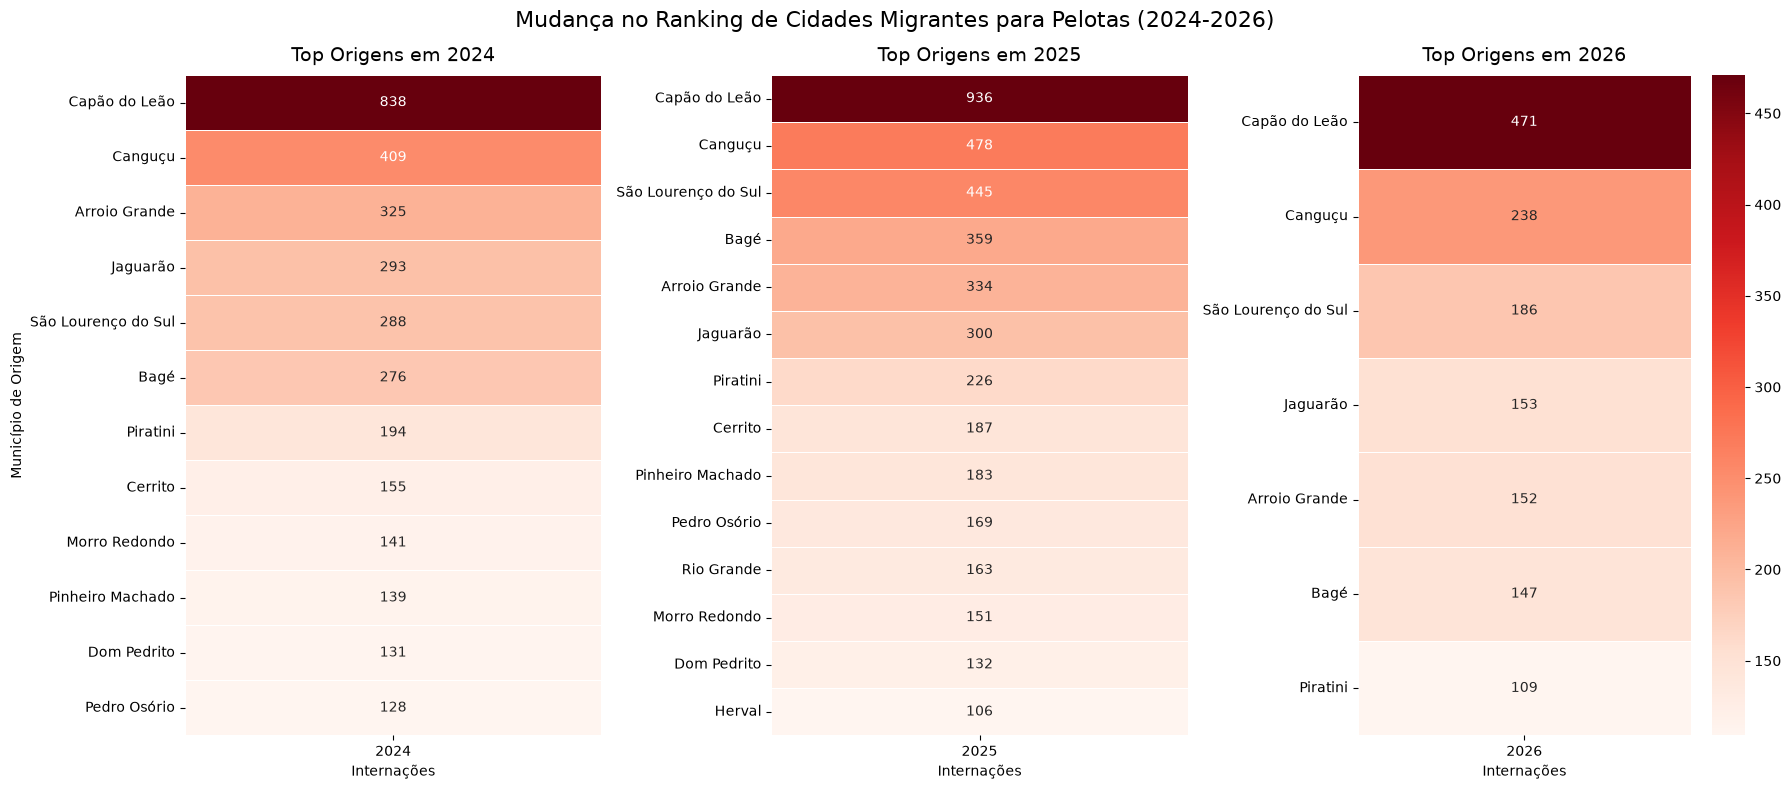

In [ ]:
# heatmap para município de Pelotas
query_heatmap = f"""
SELECT 
    dim_res.nome_municipio AS ORIGEM,
    SUBSTR(SIH.DT_INTER, 1, 4) AS ANO,
    COUNT(*) AS TOTAL_PACIENTES
FROM '{sih_glob}' AS SIH
LEFT JOIN '{ibge_path}' AS dim_res 
    ON NULLIF(TRIM(SIH.MUNIC_RES), '') = dim_res.code_ibge_6
LEFT JOIN '{ibge_path}' AS dim_mov 
    ON NULLIF(TRIM(SIH.MUNIC_MOV), '') = dim_mov.code_ibge_6
WHERE dim_mov.nome_municipio = 'Pelotas' 
  AND NULLIF(TRIM(SIH.MUNIC_RES), '') != NULLIF(TRIM(SIH.MUNIC_MOV), '')
  AND SUBSTR(SIH.DT_INTER, 1, 4) IN ('2024', '2025', '2026') 
GROUP BY dim_res.nome_municipio, ANO
HAVING COUNT(*) >= 100
ORDER BY TOTAL_PACIENTES DESC
"""

df_fluxo = con.execute(query_heatmap).df()
matriz_fluxo = df_fluxo.pivot(index='ORIGEM', columns='ANO', values='TOTAL_PACIENTES').fillna(0)

# cria 3 quadros de plotagem (1 linha, 3 colunas)
fig, axes = plt.subplots(1, 3, figsize=(18, 8))
anos = ['2024', '2025', '2026']

for i, ano in enumerate(anos):
    # verifica se o ano existe nos dados
    if ano in matriz_fluxo.columns:
        # isola a coluna do ano e ordena do maior para o menor
        df_ano = matriz_fluxo[[ano]].sort_values(by=ano, ascending=False)
        
        # remove quem teve 0 naquele ano específico para limpar a visualização
        df_ano = df_ano[df_ano[ano] > 0]
        
        sns.heatmap(
            df_ano,
            annot=True,
            fmt=".0f",
            cmap="Reds",
            linewidths=.5,
            ax=axes[i],
            cbar=(i == 2) # mostra a barra de cor apenas no último gráfico
        )
        
        axes[i].set_title(f"Top Origens em {ano}", fontsize=14, pad=10)
        axes[i].set_ylabel("Município de Origem" if i == 0 else "")
        axes[i].set_xlabel("Internações")

plt.suptitle("Mudança no Ranking de Cidades Migrantes para Pelotas (2024-2026)", fontsize=16)
plt.tight_layout()
plt.show()

# 99. Exploração das Colunas

Só por curiosidade mesmo...

In [12]:
# exploração da coluna SEXO
query_sexo = f"""
    SELECT
        SIH.SEXO,
        COUNT(*) AS TOTAL_INTERNACOES,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS PCT_TOTAL
    FROM '{sih_glob}' AS SIH
    GROUP BY SIH.SEXO
    ORDER BY TOTAL_INTERNACOES DESC
"""

df_sexo = con.execute(query_sexo).df()
display(df_sexo)

,SEXO,TOTAL_INTERNACOES,PCT_TOTAL
0,3,1080234,54.31
1,1,908932,45.69
2,4,5,0.00


In [11]:
# consulta da frequência dos códigos da coluna ESPEC (Especialidade)
query_espec = f"""
    SELECT 
        SIH.ESPEC,
        E.DESCRICAO,
        COUNT(*) AS total_internacoes,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_total
    FROM '{sih_glob}' AS SIH
    INNER JOIN '{espec_path}' AS E ON SIH.ESPEC = E.CODIGO
    GROUP BY SIH.ESPEC, E.DESCRICAO
    ORDER BY total_internacoes DESC
"""

df_espec = con.execute(query_espec).df()
display(df_espec.head(20))

,ESPEC,descricao,total_internacoes,pct_total
0,01,Cirúrgico,797735,40.10
1,03,Clínico,754763,37.94
2,02,Obstétricos,181785,9.14
3,07,Pediátricos,123422,6.20
4,05,Psiquiatria,66278,3.33
5,87,Saúde Mental (Clínico),23444,1.18
6,09,Leito Dia / Cirúrgicos,21866,1.10
7,04,Crônicos,16732,0.84
8,10,Leito Dia / Aids,1346,0.07
9,12,Leito Dia / Intercorrência Pós-Transplante,611,0.03


In [27]:
# consulta da frequência dos códigos da coluna UF_ZI
query_uf_zi = f"""
    SELECT 
        UF_ZI,
        COUNT(*) AS total_internacoes,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_total
    FROM '{sih_glob}'
    GROUP BY UF_ZI
    ORDER BY total_internacoes DESC
"""

df_uf_zi = con.execute(query_uf_zi).df()
display(df_uf_zi.head(10))

,UF_ZI,total_internacoes,pct_total
0,430000,932552,46.88
1,431490,429011,21.57
2,430510,71880,3.61
3,430460,58031,2.92
4,431440,55253,2.78
5,431340,30564,1.54
6,431680,30357,1.53
7,431870,28664,1.44
8,431720,22484,1.13
9,431140,20981,1.05


In [21]:
# MUNIC_MOV
query_munic_mov = f"""
    SELECT 
        SIH.MUNIC_MOV,
        IBGE.NOME_MUNICIPIO,
        COUNT(*) AS total_internacoes,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_total
    FROM '{sih_glob}' AS SIH
    INNER JOIN '{ibge_path}' AS IBGE
        ON SIH.MUNIC_MOV = IBGE.CODE_IBGE_6
    GROUP BY SIH.MUNIC_MOV, IBGE.NOME_MUNICIPIO
    ORDER BY total_internacoes DESC
"""

df_munic_mov = con.execute(query_munic_mov).df()
display(df_munic_mov)

,MUNIC_MOV,nome_municipio,total_internacoes,pct_total
0,431490,Porto Alegre,429011,21.57
1,431410,Passo Fundo,84398,4.24
2,430510,Caxias do Sul,71880,3.61
3,431690,Santa Maria,62058,3.12
4,430460,Canoas,58031,2.92
...,...,...,...,...
225,431112,Jaquirana,110,0.01
226,430845,Fortaleza dos Valos,91,0.00
227,430270,Butiá,45,0.00
228,430755,Estação,13,0.00


In [28]:
# consulta da frequência dos códigos da coluna RACA_COR
query_raca_cor = f"""
    SELECT 
        RACA_COR,
        COUNT(*) AS total_internacoes,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_total
    FROM '{sih_glob}'
    GROUP BY RACA_COR
    ORDER BY total_internacoes DESC
"""

df_raca_cor = con.execute(query_raca_cor).df()
display(df_raca_cor.head(10))

,RACA_COR,total_internacoes,pct_total
0,01,1700035,85.46
1,03,154591,7.77
2,02,114090,5.74
3,04,13902,0.70
4,05,6529,0.33
5,99,24,0.00


In [29]:
# consulta da frequência dos códigos da coluna INSTRU
query_instru = f"""
    SELECT 
        INSTRU,
        COUNT(*) AS total_internacoes,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_total
    FROM '{sih_glob}'
    GROUP BY INSTRU
    ORDER BY total_internacoes DESC
"""

df_instru = con.execute(query_instru).df()
display(df_instru.head(10))

,INSTRU,total_internacoes,pct_total
0,0,1963454,98.71
1,3,13250,0.67
2,2,8799,0.44
3,4,2192,0.11
4,1,1476,0.07


In [30]:
# consulta da frequência dos códigos da coluna MORTE
query_morte = f"""
    SELECT 
        MORTE,
        COUNT(*) AS total_internacoes,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_total
    FROM '{sih_glob}'
    GROUP BY MORTE
    ORDER BY total_internacoes DESC
"""

df_morte = con.execute(query_morte).df()
display(df_morte.head(10))

,MORTE,total_internacoes,pct_total
0,0,1886099,94.82
1,1,103072,5.18


In [32]:
# COMPLEX
# consulta da frequência dos códigos da coluna COMPLEX
query_complex = f"""
    SELECT 
        COMPLEX,
        COUNT(*) AS total_internacoes,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_total
    FROM '{sih_glob}'
    GROUP BY COMPLEX
    ORDER BY total_internacoes DESC
"""

df_complex = con.execute(query_complex).df()
display(df_complex.head(10))

,COMPLEX,total_internacoes,pct_total
0,02,1750206,87.99
1,03,238965,12.01
